# Import libraries

In [93]:
import sys
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.model_selection import train_test_split, KFold, RandomizedSearchCV
from sklearn.linear_model import Ridge
from sklearn.metrics import mean_absolute_error
from sklearn.ensemble import RandomForestRegressor
from xgboost import XGBRegressor
from lightgbm import LGBMRegressor
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import TensorDataset, DataLoader


# Load data

In [3]:
data_path = "/kaggle/input/competitions/allstate-claims-severity"
os.listdir(data_path)

['sample_submission.csv',
 'train.csv.zip',
 'sample_submission.csv.zip',
 'train.csv',
 'test.csv',
 'test.csv.zip']

In [4]:
df_train = pd.read_csv(f"{data_path}/train.csv")
df_test = pd.read_csv(f"{data_path}/test.csv")

# Exploratory data analysis

In [5]:
df_train.head()

,id,cat1,cat2,cat3,cat4,cat5,cat6,cat7,cat8,cat9,...,cont6,cont7,cont8,cont9,cont10,cont11,cont12,cont13,cont14,loss
0,1,A,B,A,B,A,A,A,A,B,...,0.718367,0.335060,0.30260,0.67135,0.83510,0.569745,0.594646,0.822493,0.714843,2213.18
1,2,A,B,A,A,A,A,A,A,B,...,0.438917,0.436585,0.60087,0.35127,0.43919,0.338312,0.366307,0.611431,0.304496,1283.60
2,5,A,B,A,A,B,A,A,A,B,...,0.289648,0.315545,0.27320,0.26076,0.32446,0.381398,0.373424,0.195709,0.774425,3005.09
3,10,B,B,A,B,A,A,A,A,B,...,0.440945,0.391128,0.31796,0.32128,0.44467,0.327915,0.321570,0.605077,0.602642,939.85
4,11,A,B,A,B,A,A,A,A,B,...,0.178193,0.247408,0.24564,0.22089,0.21230,0.204687,0.202213,0.246011,0.432606,2763.85


In [6]:
df_train.shape


(188318, 132)

In [7]:
df_test.shape

(125546, 131)

In [8]:
df_train.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 188318 entries, 0 to 188317
Columns: 132 entries, id to loss
dtypes: float64(15), int64(1), object(116)
memory usage: 189.7+ MB


In [9]:
df_train.describe()

,id,cont1,cont2,cont3,cont4,cont5,cont6,cont7,cont8,cont9,cont10,cont11,cont12,cont13,cont14,loss
count,188318.000000,188318.000000,188318.000000,188318.000000,188318.000000,188318.000000,188318.000000,188318.000000,188318.000000,188318.000000,188318.000000,188318.000000,188318.000000,188318.000000,188318.000000,188318.000000
mean,294135.982561,0.493861,0.507188,0.498918,0.491812,0.487428,0.490945,0.484970,0.486437,0.485506,0.498066,0.493511,0.493150,0.493138,0.495717,3037.337686
std,169336.084867,0.187640,0.207202,0.202105,0.211292,0.209027,0.205273,0.178450,0.199370,0.181660,0.185877,0.209737,0.209427,0.212777,0.222488,2904.086186
min,1.000000,0.000016,0.001149,0.002634,0.176921,0.281143,0.012683,0.069503,0.236880,0.000080,0.000000,0.035321,0.036232,0.000228,0.179722,0.670000
25%,147748.250000,0.346090,0.358319,0.336963,0.327354,0.281143,0.336105,0.350175,0.312800,0.358970,0.364580,0.310961,0.311661,0.315758,0.294610,1204.460000
50%,294539.500000,0.475784,0.555782,0.527991,0.452887,0.422268,0.440945,0.438285,0.441060,0.441450,0.461190,0.457203,0.462286,0.363547,0.407403,2115.570000
75%,440680.500000,0.623912,0.681761,0.634224,0.652072,0.643315,0.655021,0.591045,0.623580,0.566820,0.614590,0.678924,0.675759,0.689974,0.724623,3864.045000
max,587633.000000,0.984975,0.862654,0.944251,0.954297,0.983674,0.997162,1.000000,0.980200,0.995400,0.994980,0.998742,0.998484,0.988494,0.844848,121012.250000


In [10]:
df_train.dtypes

id          int64
cat1       object
cat2       object
cat3       object
cat4       object
           ...   
cont11    float64
cont12    float64
cont13    float64
cont14    float64
loss      float64
Length: 132, dtype: object

In [11]:
df_train.select_dtypes(include='number').columns

Index(['id', 'cont1', 'cont2', 'cont3', 'cont4', 'cont5', 'cont6', 'cont7',
       'cont8', 'cont9', 'cont10', 'cont11', 'cont12', 'cont13', 'cont14',
       'loss'],
      dtype='object')

In [12]:
df_train.select_dtypes(include='object').columns

Index(['cat1', 'cat2', 'cat3', 'cat4', 'cat5', 'cat6', 'cat7', 'cat8', 'cat9',
       'cat10',
       ...
       'cat107', 'cat108', 'cat109', 'cat110', 'cat111', 'cat112', 'cat113',
       'cat114', 'cat115', 'cat116'],
      dtype='object', length=116)

In [13]:
df_train.dtypes.value_counts()

object     116
float64     15
int64        1
Name: count, dtype: int64

In [14]:
print(f"Train Number of missing values: {df_train.isna().sum().sum()}")

Train Number of missing values: 0


In [15]:
print(f"Test Number of missing values: {df_test.isna().sum().sum()}")

Test Number of missing values: 0


## Analyze the Target Variable (`loss`)

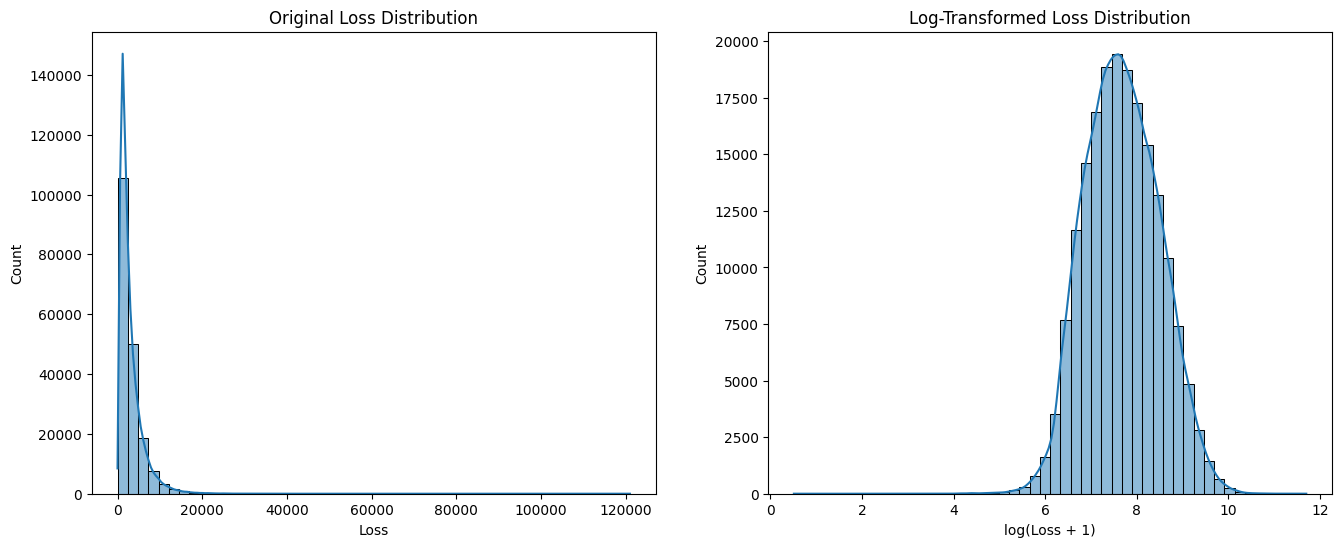

In [16]:
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Plot loss distribution
sns.histplot(df_train['loss'], bins=50, kde=True, ax=axes[0])
axes[0].set_title('Original Loss Distribution')
axes[0].set_xlabel('Loss')

# Plot log-transformed loss distribution
sns.histplot(np.log1p(df_train['loss']), bins=50, kde=True, ax=axes[1])
axes[1].set_title('Log-Transformed Loss Distribution')
axes[1].set_xlabel('log(Loss + 1)')


plt.show()

In [17]:
df_train["loss"].skew()

np.float64(3.7949583775378604)

In [18]:
np.log1p(df_train["loss"]).skew()

np.float64(0.09661958950315053)

## Analyze Correlation between Continuous Features


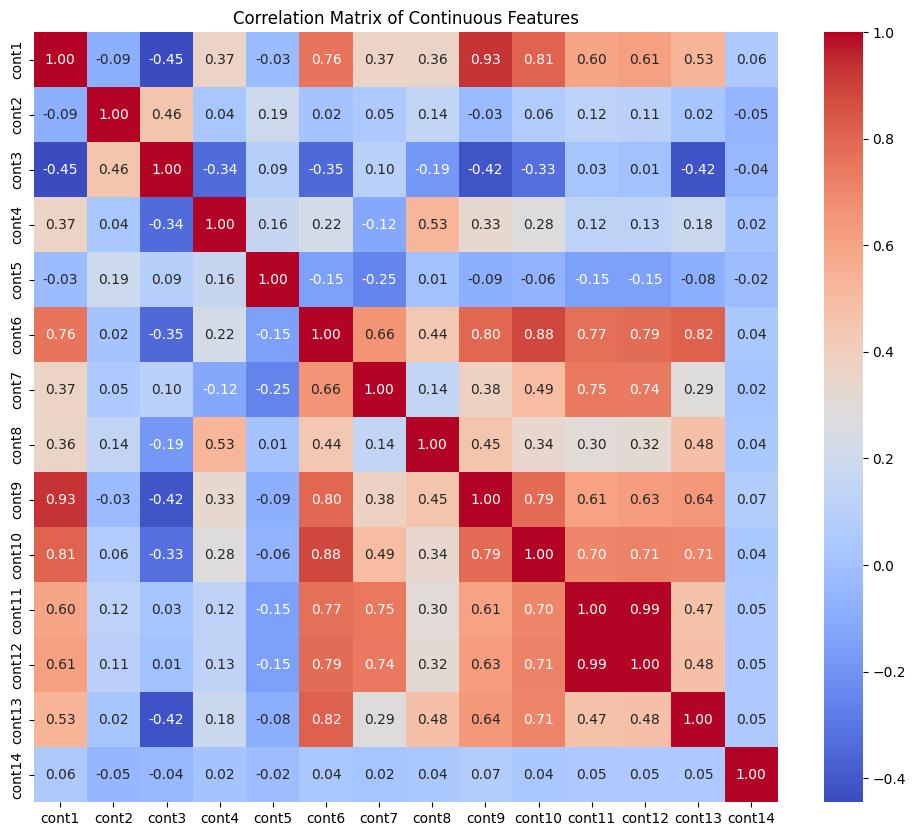

In [19]:
cont_cols = [col for col in df_train.columns if 'cont' in col]
correlation_matrix = df_train[cont_cols].corr()

plt.figure(figsize=(12, 10))
sns.heatmap(correlation_matrix, annot=True, fmt='.2f', cmap='coolwarm')
plt.title('Correlation Matrix of Continuous Features')
plt.show()

## Data Preprocessing & Feature Engineering


In [20]:
X = df_train.drop(columns=['loss'])
y = df_train['loss']

In [21]:
# Apply log1p transformation to our target variable loss
y_log = np.log1p(y)

In [22]:
# Drop 'cont12' as it is highly correlated with 'cont11' (0.99)
X_preprocessed = X.drop(columns=['cont12'])
df_test_preprocessed = df_test.drop(columns=['cont12'])

print(f"Train shape after dropping 'loss' and 'cont12': {X_preprocessed.shape}")
print(f"Test shape after dropping 'cont12': {df_test_preprocessed.shape}")

Train shape after dropping 'loss' and 'cont12': (188318, 130)
Test shape after dropping 'cont12': (125546, 130)


### Inspect Categorical Feature Cardinality

In [23]:
cat_cols = X_preprocessed.select_dtypes(include='object').columns
cardinality = X_preprocessed[cat_cols].nunique().sort_values(ascending=False)

# Display top 15 highest cardinality categorical columns
print("Top 10 highest cardinality categorical features:")
display(cardinality.head(10))

# Display summary of categories
print(f"\nTotal categorical columns: {len(cat_cols)}")
print(f"Columns with 2 unique values (binary): {sum(cardinality == 2)}")
print(f"Columns with >2 unique values: {sum(cardinality > 2)}")

Top 10 highest cardinality categorical features:


cat116    326
cat110    131
cat109     84
cat113     61
cat112     51
cat115     23
cat105     20
cat107     20
cat101     19
cat114     19
dtype: int64


Total categorical columns: 116
Columns with 2 unique values (binary): 72
Columns with >2 unique values: 44


## Categorical Encoding and Train-Validation Split

In [24]:
X_encoded = X_preprocessed.copy()
X_test_encoded = df_test_preprocessed.copy()

# Encode categorical columns
print("Encoding categorical variables...")
for col in cat_cols:
    le = LabelEncoder()
    # Fit on combined train and test to avoid unseen label issues
    combined_series = pd.concat([X_encoded[col], X_test_encoded[col]], axis=0).astype(str)
    le.fit(combined_series)

    X_encoded[col] = le.transform(X_encoded[col].astype(str))
    X_test_encoded[col] = le.transform(X_test_encoded[col].astype(str))

print("Encoding completed!")

Encoding categorical variables...
Encoding completed!


In [25]:
# Drop the 'id' column from features as it is not predictive
X_model = X_encoded.drop(columns=['id'])
X_test_model = X_test_encoded.drop(columns=['id'])

# Split into Train and Validation sets
X_train, X_valid, y_train, y_valid = train_test_split(
    X_model, y_log, test_size=0.2, random_state=42
)

print(f"Training set shape: {X_train.shape}")
print(f"Validation set shape: {X_valid.shape}")

Training set shape: (150654, 129)
Validation set shape: (37664, 129)


# Custom Cross-Validation Function

To ensure our cross-validation aligns perfectly with our preprocessing steps, we will write a custom cross-validation evaluation loop that:
1. Fits on the training folds using the log-transformed target (`y_log`).
2. Predicts on the validation fold.
3. Converts predictions back to the original dollar scale using `np.expm1()` before calculating the Mean Absolute Error.

In [26]:
def evaluate_cv_mae(model, X, y_log, n_splits=5):
    kf = KFold(n_splits=n_splits, shuffle=True, random_state=42)
    scores = []

    for train_idx, val_idx in kf.split(X):
        # Split data
        X_train_fold, X_valid_fold = X.iloc[train_idx], X.iloc[val_idx]
        y_train_log, y_valid_log = y_log.iloc[train_idx], y_log.iloc[val_idx]

        # Train the model
        model.fit(X_train_fold, y_train_log)

        # Predict and convert back from log-space
        preds_log = model.predict(X_valid_fold)
        preds_original = np.expm1(preds_log)
        y_va_original = np.expm1(y_valid_log)

        # Calculate MAE on original scale
        mae = mean_absolute_error(y_va_original, preds_original)
        scores.append(mae)

    return np.array(scores)

# Baseline Model (Ridge Regression)

In [27]:
print("Training Ridge Regression baseline model...")
ridge_model = Ridge(alpha=1.0, random_state=42)
ridge_model.fit(X_train, y_train)

# Predict and convert back from log-space using expm1
ridge_preds_log = ridge_model.predict(X_valid)
ridge_mae = mean_absolute_error(np.expm1(y_valid), np.expm1(ridge_preds_log))

print(f"Ridge Regression Baseline MAE: {ridge_mae:.4f}")

Training Ridge Regression baseline model...
Ridge Regression Baseline MAE: 1287.2063


## Cross Validation

In [28]:
# Run correct CV on our Ridge baseline
ridge_cv_score = evaluate_cv_mae(ridge_model, X_model, y_log, n_splits=5)
print(f"Ridge CV MAE Scores: {ridge_cv_score}")
print(f"Ridge CV MAE Mean: {ridge_cv_score.mean():.4f} (std: {ridge_cv_score.std():.4f})")

Ridge CV MAE Scores: [1287.20634953 1301.85211437 1293.97407608 1296.4761195  1273.09690884]
Ridge CV MAE Mean: 1290.5211 (std: 9.9032)


# Random Forest model

In [29]:
rf_model = RandomForestRegressor(n_estimators = 100, max_depth=10,
                                 max_samples=0.5,n_jobs=-1,random_state=42)
rf_model.fit(X_train, y_train)

RandomForestRegressor(max_depth=10, max_samples=0.5, n_jobs=-1, random_state=42)

In [30]:
rf_preds_log = rf_model.predict(X_valid)
rf_mae = mean_absolute_error(np.expm1(y_valid), np.expm1(rf_preds_log))

print(f"Random Forest MAE: {rf_mae:.4f}")

Random Forest MAE: 1233.0022


## Cross Validation

In [31]:
rf_cv_score = evaluate_cv_mae(rf_model, X_model, y_log, n_splits=5)

In [34]:
print(f"RF CV MAE Scores: {rf_cv_score}")
print(f"RF CV MAE Mean: {rf_cv_score.mean():.4f} (std: {rf_cv_score.std():.4f})")

RF CV MAE Scores: [1233.60554237 1251.11802784 1252.47739627 1253.90735055 1236.34762461]
RF CV MAE Mean: 1245.4912 (std: 8.6738)


# XGBoost Regressor Model

In [35]:
xgb_model = XGBRegressor(n_estimators = 100, learning_rate = 0.1,
                         max_depth = 10,
                         random_state = 42)

In [36]:
xgb_model.fit(X_train, y_train)

XGBRegressor(base_score=None, booster=None, callbacks=None,
             colsample_bylevel=None, colsample_bynode=None,
             colsample_bytree=None, device=None, early_stopping_rounds=None,
             enable_categorical=True, eval_metric=None, feature_types=None,
             feature_weights=None, gamma=None, grow_policy=None,
             importance_type=None, interaction_constraints=None,
             learning_rate=0.1, max_bin=None, max_cat_threshold=None,
             max_cat_to_onehot=None, max_delta_step=None, max_depth=10,
             max_leaves=None, min_child_weight=None, missing=nan,
             monotone_constraints=None, multi_strategy=None, n_estimators=100,
             n_jobs=None, num_parallel_tree=None, ...)

In [37]:
xgb_preds_log = xgb_model.predict(X_valid)

In [38]:
xgb_mae = mean_absolute_error(np.expm1(y_valid), np.expm1(xgb_preds_log))
print(f"XGBoost Validation MAE: {xgb_mae:.4f}")

XGBoost Validation MAE: 1149.1907


## Cross Validation

In [39]:
xgb_cv_score = evaluate_cv_mae(xgb_model, X_model, y_log, n_splits=5)

In [40]:
print(f"XGB CV MAE Scores: {xgb_cv_score}")
print(f"XGB CV MAE Mean: {xgb_cv_score.mean():.4f} (std: {xgb_cv_score.std():.4f})")

XGB CV MAE Scores: [1149.71401317 1166.04921565 1165.55157697 1163.31331168 1145.70249349]
XGB CV MAE Mean: 1158.0661 (std: 8.6013)


# LightGBM Regressor Model

In [41]:
lgbm_model = LGBMRegressor(
    n_estimators=100,
    max_depth=10,
    learning_rate=0.05,
    num_leaves=30,
    subsample=0.8,
    colsample_bytree=0.8,
    random_state=42,
    n_jobs=-1,
    verbose=-1
)

In [42]:
lgbm_model.fit(X_train, y_train)

LGBMRegressor(colsample_bytree=0.8, learning_rate=0.05, max_depth=10, n_jobs=-1,
              num_leaves=30, random_state=42, subsample=0.8, verbose=-1)

In [43]:
lgbm_preds_log = lgbm_model.predict(X_valid)
lgbm_mae = mean_absolute_error(np.expm1(y_valid), np.expm1(lgbm_preds_log))

print(f"LightGBM Validation MAE: {lgbm_mae:.4f}")

LightGBM Validation MAE: 1183.8755


## Cross Validation 

In [44]:
lgbm_cv_score = evaluate_cv_mae(lgbm_model, X_model, y_log, n_splits=5)
print(f"LightGBM CV MAE Scores: {lgbm_cv_score}")
print(f"LightGBM CV MAE Mean: {lgbm_cv_score.mean():.4f} (std: {lgbm_cv_score.std():.4f})")

LightGBM CV MAE Scores: [1183.87545695 1201.68355799 1201.58614224 1201.77676377 1182.97270151]
LightGBM CV MAE Mean: 1194.3789 (std: 8.9494)


# Pytorch Model

In [45]:
# Set device
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Using device: {device}")

Using device: cpu


In [46]:
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_valid_scaled = scaler.transform(X_valid)

In [47]:
X_train_tensor = torch.tensor(X_train_scaled, dtype=torch.float32)
y_train_tensor = torch.tensor(y_train.values, dtype=torch.float32).view(-1, 1)

X_valid_tensor = torch.tensor(X_valid_scaled, dtype=torch.float32)
y_valid_tensor = torch.tensor(y_valid.values, dtype=torch.float32).view(-1, 1)


In [48]:
train_dataset = TensorDataset(X_train_tensor, y_train_tensor)
valid_dataset= TensorDataset(X_valid_tensor, y_valid_tensor)


In [49]:
train_loader = DataLoader(train_dataset, batch_size=256, shuffle=True)
valid_loader = DataLoader(valid_dataset, batch_size=256, shuffle=False)


In [50]:
n_features = X_model.shape[1]
n_epochs = 15
learning_rate = 0.001

In [51]:
torch.manual_seed(42)
mlp_model = nn.Sequential(
    nn.Linear(n_features, 256),
    nn.ReLU(),
    nn.Linear(256, 128),
    nn.ReLU(),
    nn.Linear(128, 64),
    nn.ReLU(),
    nn.Linear(64, 1)
)

mlp_model = mlp_model.to(device)

In [52]:
optimizer = torch.optim.Adam(mlp_model.parameters(), lr=learning_rate)
mse = nn.MSELoss()

In [53]:
def train(model, optimizer, criterion, train_loader, n_epochs):
    model.train()
    for epoch in range(n_epochs):
        total_loss = 0.0
        for X_batch, y_batch in train_loader:
            X_batch, y_batch = X_batch.to(device), y_batch.to(device)
            y_pred = model(X_batch)
            loss = criterion(y_pred, y_batch)
            total_loss += loss.item() * X_batch.size(0)
            loss.backward()
            optimizer.step()
            optimizer.zero_grad()
        mean_loss = total_loss / len(train_loader.dataset)
        print(f"Epoch {epoch + 1}/{n_epochs}, Loss: {mean_loss:.4f}")

In [54]:
train(mlp_model, optimizer, mse, train_loader, n_epochs)

Epoch 1/15, Loss: 1.8334
Epoch 2/15, Loss: 0.3502
Epoch 3/15, Loss: 0.3325
Epoch 4/15, Loss: 0.3260
Epoch 5/15, Loss: 0.3191
Epoch 6/15, Loss: 0.3160
Epoch 7/15, Loss: 0.3136
Epoch 8/15, Loss: 0.3125
Epoch 9/15, Loss: 0.3057
Epoch 10/15, Loss: 0.3049
Epoch 11/15, Loss: 0.3051
Epoch 12/15, Loss: 0.3026
Epoch 13/15, Loss: 0.2982
Epoch 14/15, Loss: 0.2986
Epoch 15/15, Loss: 0.2960


In [68]:
def evaluate(model, data_loader):
    model.eval()
    prediction_log = []
    y_true_log = []
    with torch.no_grad():
        for X_batch, y_batch in data_loader:
            X_batch, y_batch = X_batch.to(device), y_batch.to(device)
            y_pred = model(X_batch)
            prediction_log.extend(y_pred.cpu().numpy().flatten())
            y_true_log.extend(y_batch.cpu().numpy().flatten())
            
        predictions = np.expm1(np.array(prediction_log))
        y_true = np.expm1(np.array(y_true_log))
        mae = mean_absolute_error(y_true, predictions)
    return mae

In [69]:
mlp_mse = evaluate(mlp_model, valid_loader)
mlp_mse

1246.21826171875

## Cross Validation 

In [57]:
def pytorch_cross_val(model_fn, X, y, n_splits=5, batch_size=32, n_epochs=50, lr=0.001):
    kf = KFold(n_splits=n_splits, shuffle=True, random_state=42)
    
    cv_maes = []

    for fold, (train_idx, valid_idx) in enumerate(kf.split(X)):
        print(f"Fold {fold + 1}/{n_splits}")

        # Split data
        X_fold_train = X[train_idx]
        y_fold_train = y[train_idx]

        X_fold_valid = X[valid_idx]
        y_fold_valid = y[valid_idx]

        # Create datasets
        train_dataset = TensorDataset(
            X_fold_train,
            y_fold_train
        )

        valid_dataset = TensorDataset(
            X_fold_valid,
            y_fold_valid
        )

        # Create DataLoaders
        train_loader = DataLoader(
            train_dataset,
            batch_size=batch_size,
            shuffle=True
        )

        valid_loader = DataLoader(
            valid_dataset,
            batch_size=batch_size,
            shuffle=False
        )

        # Create a NEW model for each fold
        model = model_fn().to(device)

        optimizer = torch.optim.Adam(
            model.parameters(),
            lr=lr
        )

        criterion = nn.MSELoss()

        # Train
        train(
            model,
            optimizer,
            criterion,
            train_loader,
            n_epochs
        )

        # Evaluate
        mae = evaluate(
            model,
            valid_loader
        )

        cv_maes.append(mae)

        print(f"Fold MAE: {mae:.4f}\n")

    # Average CV MAE
    cv_mae = np.mean(cv_maes)

    print(f"Mean CV MAE: {cv_mae:.4f}")
    print(f"CV MAE Std: {np.std(cv_maes):.4f}")

    return cv_mae, cv_maes

In [58]:
def create_mlp():
    return nn.Sequential(
    nn.Linear(n_features, 256),
    nn.ReLU(),
    nn.Linear(256, 128),
    nn.ReLU(),
    nn.Linear(128, 64),
    nn.ReLU(),
    nn.Linear(64, 1)
)

In [59]:
pytorch_cv_mae, fold_maes = pytorch_cross_val(
    create_mlp,
    X_train_tensor,
    y_train_tensor,
    n_splits=5,
    batch_size=32,
    n_epochs=10,
    lr=0.001
)

Fold 1/5
Epoch 1/10, Loss: 0.7030
Epoch 2/10, Loss: 0.3787
Epoch 3/10, Loss: 0.3529
Epoch 4/10, Loss: 0.3389
Epoch 5/10, Loss: 0.3301
Epoch 6/10, Loss: 0.3216
Epoch 7/10, Loss: 0.3153
Epoch 8/10, Loss: 0.3132
Epoch 9/10, Loss: 0.3084
Epoch 10/10, Loss: 0.3050
Fold MAE: 1174.2964

Fold 2/5
Epoch 1/10, Loss: 0.6735
Epoch 2/10, Loss: 0.3747
Epoch 3/10, Loss: 0.3525
Epoch 4/10, Loss: 0.3387
Epoch 5/10, Loss: 0.3290
Epoch 6/10, Loss: 0.3212
Epoch 7/10, Loss: 0.3143
Epoch 8/10, Loss: 0.3096
Epoch 9/10, Loss: 0.3075
Epoch 10/10, Loss: 0.3044
Fold MAE: 1167.0532

Fold 3/5
Epoch 1/10, Loss: 0.6833
Epoch 2/10, Loss: 0.3783
Epoch 3/10, Loss: 0.3566
Epoch 4/10, Loss: 0.3426
Epoch 5/10, Loss: 0.3323
Epoch 6/10, Loss: 0.3266
Epoch 7/10, Loss: 0.3197
Epoch 8/10, Loss: 0.3143
Epoch 9/10, Loss: 0.3098
Epoch 10/10, Loss: 0.3078
Fold MAE: 1153.2864

Fold 4/5
Epoch 1/10, Loss: 0.7218
Epoch 2/10, Loss: 0.3755
Epoch 3/10, Loss: 0.3535
Epoch 4/10, Loss: 0.3420
Epoch 5/10, Loss: 0.3331
Epoch 6/10, Loss: 0.324

# Model Comparison Summary

In [60]:
model_names = ['Ridge Baseline', 'Random Forest', 'XGBoost', 'LightGBM', 'PyTorch MLP']

validation_maes = [
    ridge_mae,
    rf_mae,
    xgb_mae if 'xgb_mae' in locals() else np.nan,
    lgbm_mae if 'lgbm_mae' in locals() else np.nan,
    mlp_mse if 'mlp_mse' in locals() else np.nan
]


cv_means = [
    ridge_cv_score.mean() if 'ridge_cv_score' in locals() else np.nan,
    rf_cv_score.mean() if 'rf_cv_score' in locals() else np.nan,
    xgb_cv_score.mean() if 'xgb_cv_score' in locals() else np.nan,
    lgbm_cv_score.mean() if 'lgbm_cv_score' in locals() else np.nan,
    pytorch_cv_mae.mean() if 'pytorch_cv_mae' in locals() else np.nan
]

In [61]:
results_df = pd.DataFrame({
    'Model': model_names,
    'Validation MAE ($)': validation_maes,
    'Mean CV MAE ($)': cv_means
})

In [62]:
results_df.sort_values(by='Mean CV MAE ($)', ascending=True)

,Model,Validation MAE ($),Mean CV MAE ($)
2,XGBoost,1149.190745,1158.066122
4,PyTorch MLP,1246.218262,1165.123877
3,LightGBM,1183.875457,1194.378924
1,Random Forest,1233.002181,1245.491188
0,Ridge Baseline,1287.206350,1290.521114


In [63]:
results_df.to_csv("model_comparison.csv")

# XGBoost hyperparameter tuning

In [71]:
param_distributions = {
    "n_estimators": [100, 200, 300, 500],
    "learning_rate": [0.01, 0.05, 0.1],
    "max_depth": [5, 7, 10],
    "subsample": [0.6, 0.8, 1.0],
    "colsample_bytree": [0.7, 0.9, 1.0]
}

In [72]:
random_search = RandomizedSearchCV(
    estimator=xgb_model,
    param_distributions=param_distributions,
    n_iter=10,
    scoring="neg_mean_absolute_error",
    cv=5,
    random_state=42,
    n_jobs=-1,
    verbose=1
)

In [73]:
random_search.fit(X_train, y_train)

Fitting 5 folds for each of 10 candidates, totalling 50 fits


RandomizedSearchCV(cv=5,
                   estimator=XGBRegressor(base_score=None, booster=None,
                                          callbacks=None,
                                          colsample_bylevel=None,
                                          colsample_bynode=None,
                                          colsample_bytree=None, device=None,
                                          early_stopping_rounds=None,
                                          enable_categorical=True,
                                          eval_metric=None, feature_types=None,
                                          feature_weights=None, gamma=None,
                                          grow_policy=None,
                                          importance_type=None,
                                          interaction_constraints...
                                          min_child_weight=None, missing=nan,
                                          monotone_constraints=None,
                                          multi_strategy=None, n_estimators=100,
                                          n_jobs=None, num_parallel_tree=None, ...),
                   n_jobs=-1,
                   param_distributions={'colsample_bytree': [0.7, 0.9, 1.0],
                                        'learning_rate': [0.01, 0.05, 0.1],
                                        'max_depth': [5, 7, 10],
                                        'n_estimators': [100, 200, 300, 500],
                                        'subsample': [0.6, 0.8, 1.0]},
                   random_state=42, scoring='neg_mean_absolute_error',
                   verbose=1)

In [74]:
random_search.best_params_

{'subsample': 0.8,
 'n_estimators': 200,
 'max_depth': 7,
 'learning_rate': 0.1,
 'colsample_bytree': 0.9}

In [75]:
- random_search.best_score_

np.float64(0.4182525679089313)

In [80]:
best_xgb = random_search.best_estimator_
y_valid_pred_best = best_xgb.predict(X_valid)

best_xgb_mae = mean_absolute_error(
    np.expm1(y_valid),
    np.expm1(y_valid_pred_best)
)


In [81]:
best_xgb_mae

1141.7776865578833

# Submission

In [83]:
test_pred_log = best_xgb.predict(X_test_model)
test_pred = np.expm1(test_pred_log)

In [88]:
submission = pd.DataFrame({
    "id": df_test["id"],
    "loss": test_pred
})

In [90]:
submission.to_csv("submission.csv", index=False)